# Worked Example: Midterm Project, Movies Based on Video Games

**ECON 3916 · a worked example for the midterm, built in class on Wed 4 Nov**

This notebook is the midterm starter, filled in for one small question, so you can see what each
section looks like when it is done. Lay it beside your own notebook: same headings, same order.

It is an example of the *process*, not a model answer to copy. Your question, data and words are your own,
and your project stays **no AI** throughout.

## Start here

1. In Colab, run the cells top to bottom. The cell after Setup downloads the three data files from the repository if they are not already here.
2. To download fresh copies from the original sources instead, run `get_data.py` (it rewrites `data/`). Every number in the example report is printed by the last code cell.

## Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# Opened in Colab from GitHub? Then the data/ folder is not here yet: download it from the repository.
import os, urllib.request
REPO_RAW = "https://raw.githubusercontent.com/RyanPiao/econ3916-midterm-example/main/data/"
os.makedirs("data", exist_ok=True)
for name in ["films_wikipedia.csv", "directors_wikidata.csv", "cpi_fred.csv"]:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(REPO_RAW + name, f"data/{name}")
print(sorted(os.listdir("data")))

['cpi_fred.csv', 'directors_wikidata.csv', 'films_wikipedia.csv']


## Data provenance

In [3]:
SOURCE_URL = "https://en.wikipedia.org/wiki/List_of_films_based_on_video_games"   # + Wikidata, FRED CPIAUCSL
DOWNLOAD_DATE = "2026-11-03"
FILE_NAME = "data/films_wikipedia.csv"

**Who collected it, for what purpose, what is missing and why?**

Wikipedia editors compiled the table; each budget and gross cites Box Office Mojo or The Numbers, which collect
studio-reported figures for the trade press. Budgets are studio *claims*: they are rounded, sometimes a range,
and missing for small releases. Grosses are complete only for films that have finished their run, so 2026
releases are understated. Directors' birth dates come from Wikidata; a few directors have no page there.
The CPI is the BLS CPI-U from FRED, used to put every dollar in 2024 prices.

## Line 1 · Where it comes from: the first read

In [4]:
raw = pd.read_csv(FILE_NAME)
print(raw.shape)
print(raw[["Title", "Director", "Release date", "Budget", "Worldwide box office"]].head(3).to_string())

(68, 12)
               Title                    Director       Release date             Budget Worldwide box office
0  Super Mario Bros.  Rocky MortonAnnabel Jankel       May 28, 1993  $42–48 million[2]       $20,929,518[3]
1      Double Dragon                James Yukich   November 4, 1994    $7.8 million[6]        $2,341,309[7]
2     Street Fighter          Steven E. de Souza  December 23, 1994    $35 million[10]      $99,433,436[11]


## Line 2 · Its shape: what is one row?

In [5]:
films = raw.rename(columns={"Title": "title", "Director": "director", "Release date": "released",
                            "Budget": "budget_text", "Worldwide box office": "gross_text",
                            "Rotten Tomatoes": "rt_text"})
films["year"] = films["released"].str.extract(r"((?:19|20)\d\d)", expand=False).astype(int)

# Is the title a key? Three titles appear twice: remakes.
print("Repeated titles:", films["title"].duplicated().sum())
print(films.loc[films["title"].duplicated(keep=False), ["title", "year"]].sort_values("title").to_string(index=False))
print("Repeated title + year:", films.duplicated(["title", "year"]).sum())

Repeated titles: 3
         title  year
 Mortal Kombat  1995
 Mortal Kombat  2021
 Resident Evil  2002
 Resident Evil  2026
Street Fighter  1994
Street Fighter  2026
Repeated title + year: 0


In [6]:
def to_dollars(text):
    # "$42–48 million[2]" -> 45,000,000; anything not in US dollars (a £ budget, N/A) -> NaN
    if pd.isna(text):
        return np.nan
    s = re.sub(r"\[.*?\]", "", str(text)).replace(",", "").strip()
    if not s.startswith("$"):
        return np.nan
    nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", s)]
    value = np.mean(nums[:2]) if "–" in s else nums[0]
    return value * 1e6 if "million" in s else value * 1e9 if "billion" in s else value

films["budget"] = films["budget_text"].map(to_dollars)
films["gross"] = films["gross_text"].map(to_dollars)
not_usd = films["budget_text"].notna() & films["budget"].isna()
print("Budgets not in US dollars:", films.loc[not_usd, ["title", "budget_text"]].values.tolist())

Budgets not in US dollars: [['Moshi Monsters: The Movie', '£2.3\xa0million[285]']]


## Line 3 · What is missing

In [7]:
print(films[["budget", "gross", "rt_text"]].isna().sum().to_string())
print()
print("Missing budget, by format:")
print(films.groupby("format")["budget"].apply(lambda b: b.isna().sum()).to_string())

budget     7
gross      1
rt_text    0

Missing budget, by format:
format
animated       6
live-action    1


## Line 4 · The one join

In [8]:
directors = pd.read_csv("data/directors_wikidata.csv")
naive = films.merge(directors[["director", "born"]], on="director", how="left", indicator=True)
print(len(films), "films in,", len(naive), "rows out")
print(naive["_merge"].value_counts().to_string())
print("Not matched:", naive.loc[naive["_merge"] == "left_only", "director"].tolist())

68 films in, 68 rows out
_merge
both          58
left_only     10
right_only     0
Not matched: ['Rocky MortonAnnabel Jankel', 'James Yukich', 'Mike Cuff and Scott Windhauser', 'Wip Vernooij', 'Gun Ho Jung', 'Clay KaytisFergal Reilly', 'Takanori Tsujimoto', 'Aaron HorvathMichael Jelenic', 'Ricard Cussó', 'Aaron HorvathMichael Jelenic']


In [9]:
# Co-directors come out of the table glued together ("Rocky MortonAnnabel Jankel"). Key on the first one listed.
known = sorted(directors["director"], key=len, reverse=True)
def first_director(cell):
    return next((k for k in known if cell.startswith(k)), cell.split(" and ")[0])

films["first_director"] = films["director"].map(first_director)
df = films.merge(directors[["director", "born"]].rename(columns={"director": "first_director"}),
                 on="first_director", how="left", indicator=True, validate="many_to_one")
print(df["_merge"].value_counts().to_string())
print("Matched but no birth date on Wikidata:", df.loc[(df["_merge"] == "both") & df["born"].isna(), "first_director"].tolist())

_merge
both          62
left_only      6
right_only     0
Matched but no birth date on Wikidata: ['Dwight Little', 'Jared Hess']


In [10]:
# One unit system: every dollar in 2024 prices, joined on release year.
cpi = pd.read_csv("data/cpi_fred.csv", parse_dates=["observation_date"])
cpi = cpi.groupby(cpi["observation_date"].dt.year)["CPIAUCSL"].mean().rename_axis("year").rename("cpi").reset_index()
df = df.drop(columns="_merge").merge(cpi, on="year", how="left", validate="many_to_one")
to_2024 = cpi.set_index("year").loc[2024, "cpi"] / df["cpi"]
df["gross_m"] = df["gross"] * to_2024 / 1e6      # $ millions, 2024 prices
df["budget_m"] = df["budget"] * to_2024 / 1e6
df["dir_age"] = df["year"] - pd.to_numeric(df["born"].str[:4])
df["animated"] = (df["format"] == "animated").astype(int)
print(df[["title", "year", "gross", "gross_m"]].head(3).to_string(index=False))

            title  year      gross    gross_m
Super Mario Bros.  1993 20929518.0  45.444204
    Double Dragon  1994  2341309.0   4.955064
   Street Fighter  1994 99433436.0 210.437420


## Section 1: The Question and the Data (20 pts)

**Question.** Among English-language films based on video games, 1993–2025, do films by older directors earn more
at the worldwide box office, holding the release year and the format (live-action or animated) constant?

**Sample rule.** Drop 2026 releases (their runs are not over) and films missing a dollar budget, a gross or the
director's age. The rule is written down before the model is run.

In [11]:
sample = df[(df["year"] <= 2025)].dropna(subset=["gross_m", "budget_m", "dir_age"]).copy()
sample["log_gross"] = np.log(sample["gross_m"])
sample["log_budget"] = np.log(sample["budget_m"])
print("Films in the table:", len(df), "  in the sample:", len(sample))

table1 = (sample[["gross_m", "budget_m", "dir_age", "year"]]
          .describe().T[["mean", "std", "min", "max"]].round(1))
table1.index = ["Worldwide gross ($m, 2024)", "Budget ($m, 2024)", "Director's age at release (years)", "Release year"]
table1

Films in the table: 68   in the sample: 51


,mean,std,min,max
"Worldwide gross ($m, 2024)",232.1,243.7,0.2,1401.0
"Budget ($m, 2024)",85.7,58.9,7.5,251.7
Director's age at release (years),44.7,7.7,30.0,68.0
Release year,2011.6,8.9,1993.0,2025.0


In [12]:
# Section 1 self-check (from the starter)
UNIT = "film"
OUTCOME = "gross_m"
MAIN_X = "dir_age"
CONTROLS = ["year", "animated"]
print(f"Rows: {len(sample):,}   One row is: {UNIT}")
print(sample[[OUTCOME, MAIN_X, *CONTROLS]].isna().sum().to_string())
print(f"Skew of {OUTCOME}: {sample[OUTCOME].skew():.2f}   after a log: {sample['log_gross'].skew():.2f}")

Rows: 51   One row is: film
gross_m     0
dir_age     0
year        0
animated    0
Skew of gross_m: 2.35   after a log: -1.50


## Section 2: Descriptive Evidence (20 pts)

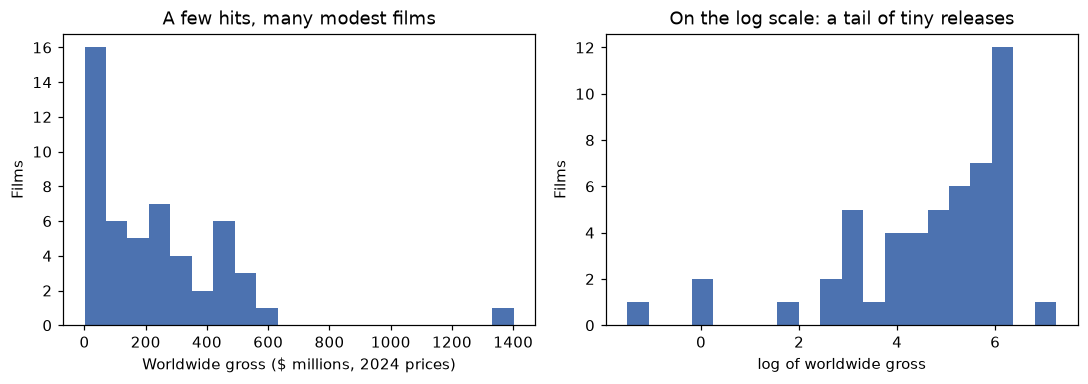

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(sample["gross_m"], bins=20, color="#4C72B0")
ax[0].set(xlabel="Worldwide gross ($ millions, 2024 prices)", ylabel="Films",
          title="A few hits, many modest films")
ax[1].hist(sample["log_gross"], bins=20, color="#4C72B0")
ax[1].set(xlabel="log of worldwide gross", ylabel="Films", title="On the log scale: a tail of tiny releases")
plt.tight_layout(); plt.show()

*Figure 1. Gross is skewed right: a few films earn over a billion dollars, so the model uses its log. The log shows the opposite tail, a handful of films that barely opened.*

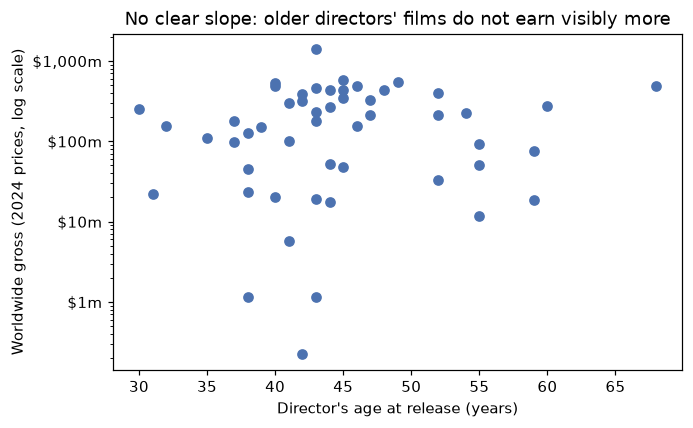

In [14]:
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.scatter(sample["dir_age"], sample["gross_m"], color="#4C72B0")
ax.set_yscale("log")
ax.set_yticks([1, 10, 100, 1000], ["$1m", "$10m", "$100m", "$1,000m"])
ax.set(xlabel="Director's age at release (years)", ylabel="Worldwide gross (2024 prices, log scale)",
       title="No clear slope: older directors' films do not earn visibly more")
plt.tight_layout(); plt.show()

*Figure 2. Across directors aged 30 to 68 at release, the films' grosses show no visible trend with age.*

## Section 3: The Model (25 pts)

In [15]:
m1 = smf.ols("log_gross ~ dir_age", sample).fit(cov_type="HC1")
m2 = smf.ols("log_gross ~ dir_age + year + animated", sample).fit(cov_type="HC1")
m3 = smf.ols("log_gross ~ dir_age + year + animated + log_budget", sample).fit(cov_type="HC1")

def regtable(models, names):
    rows = {}
    for name, m in zip(names, models):
        col = {}
        for v in ["dir_age", "year", "animated", "log_budget", "Intercept"]:
            if v in m.params:
                col[v] = f"{m.params[v]:.3f}"
                col[v + " (se)"] = f"({m.bse[v]:.3f})"
        col["N"], col["R²"] = f"{int(m.nobs)}", f"{m.rsquared:.2f}"
        rows[name] = col
    return pd.DataFrame(rows).fillna("")

regtable([m1, m2, m3], ["(1) Age only", "(2) Main", "(3) Adds budget"])

,(1) Age only,(2) Main,(3) Adds budget
dir_age,0.026,0.024,-0.028
dir_age (se),(0.025),(0.027),(0.022)
Intercept,3.448,-62.267,-98.586
Intercept (se),(1.183),(48.203),(41.966)
N,51,51,51
R²,0.01,0.06,0.45
year,,0.033,0.049
year (se),,(0.024),(0.021)
animated,,0.683,0.039
animated (se),,(0.717),(0.453)


In [16]:
b, lo, hi = m2.params["dir_age"], *m2.conf_int().loc["dir_age"]
pct = lambda x: 100 * (np.exp(x) - 1)
print(f"Main model: one more year of director age -> {pct(b):+.1f}% gross (95% CI {pct(lo):+.1f}% to {pct(hi):+.1f}%)")
print(f"Animated vs live-action: {pct(m2.params['animated']):+.0f}%")
budget_on_age = smf.ols("log_budget ~ dir_age + year + animated", sample).fit(cov_type="HC1")
print(f"Older directors get bigger budgets: {pct(budget_on_age.params['dir_age']):+.1f}% per year of age")
print(f"With budget held fixed, the age coefficient is {pct(m3.params['dir_age']):+.1f}%")

Main model: one more year of director age -> +2.4% gross (95% CI -3.0% to +8.0%)
Animated vs live-action: +98%
Older directors get bigger budgets: +3.3% per year of age
With budget held fixed, the age coefficient is -2.7%


**Roles of the controls.** *Release year* is a confounder: box office and the age of the directors studios hire both
changed over three decades. *Animated* is a confounder: animation directors and animated grosses differ from live-action.
*Budget* is a **bad control** for this question: an older director gets a bigger budget, and the budget raises the gross,
so budget sits on the path from age to gross (a mediator, Topic 10). Column 3 holds it fixed and answers a different
question (the direct path only): the point estimate on age changes sign, but neither column's estimate is
distinguishable from zero. The headline is column 2, the total association.

## Section 4: Diagnostics (20 pts)

Breusch-Pagan p = 0.88
VIF: {'dir_age': np.float64(1.03), 'year': np.float64(1.04), 'animated': np.float64(1.03)}
Largest Cook's distance:
title
Ratchet & Clank      0.156
Werewolves Within    0.134
Postal               0.082


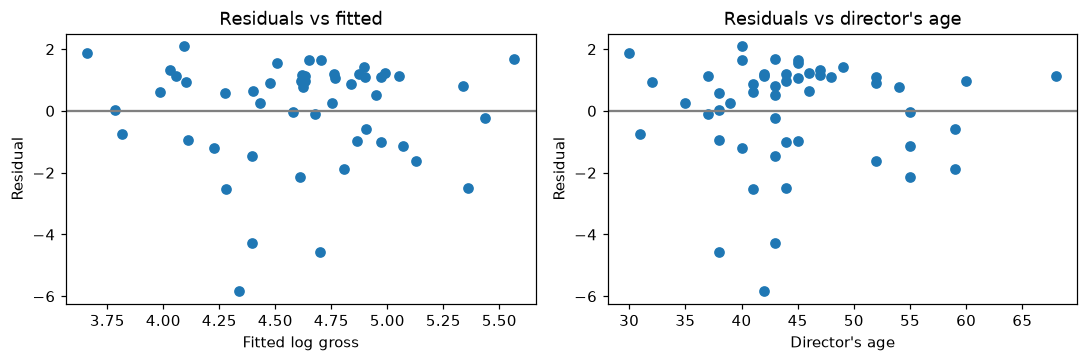

In [17]:
ols2 = smf.ols("log_gross ~ dir_age + year + animated", sample).fit()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].scatter(ols2.fittedvalues, ols2.resid); ax[0].axhline(0, color="grey")
ax[0].set(xlabel="Fitted log gross", ylabel="Residual", title="Residuals vs fitted")
ax[1].scatter(sample["dir_age"], ols2.resid); ax[1].axhline(0, color="grey")
ax[1].set(xlabel="Director's age", ylabel="Residual", title="Residuals vs director's age")
plt.tight_layout(); plt.show()

bp_p = het_breuschpagan(ols2.resid, ols2.model.exog)[1]
print(f"Breusch-Pagan p = {bp_p:.2f}")
X = ols2.model.exog
print("VIF:", {n: round(variance_inflation_factor(X, i), 2) for i, n in enumerate(ols2.model.exog_names) if n != "Intercept"})
cooks = pd.Series(ols2.get_influence().cooks_distance[0], index=sample["title"])
print("Largest Cook's distance:"); print(cooks.nlargest(3).round(3).to_string())

In [18]:
# Two of the three biggest Cook's distances are films that barely opened (Werewolves Within, Postal).
# Drop every film under $5m and report the estimate with and without them.
small = sample["gross_m"] < 5
m2_wide = smf.ols("log_gross ~ dir_age + year + animated", sample[~small]).fit(cov_type="HC1")
print(f"Without the {small.sum()} films under $5m: age {pct(m2_wide.params['dir_age']):+.1f}% "
      f"(se {100*m2_wide.bse['dir_age']:.1f} points), N = {int(m2_wide.nobs)}")

Without the 3 films under $5m: age +0.1% (se 2.4 points), N = 48


## Section 5: Threats and Conclusion (10 pts)

For the age coefficient to be causal, nothing that drives a director's age at hiring could also drive the gross.
That fails: studios hand big franchise sequels to experienced directors, and franchise sequels earn more. This sample
has no franchise variable, so the estimate is a **conditional association**, and it is small and imprecise.
With another month: code each film's franchise and whether it is a sequel, and add the director's number of earlier films.

## Numbers my report quotes

In [19]:
REPORT_NUMBERS = {
    "Line 1: rows read": len(raw),
    "Line 2: repeated titles": int(films["title"].duplicated().sum()),
    "Line 3: missing budgets": int(films["budget"].isna().sum()),
    "Line 4: naive merge unmatched": int((naive["_merge"] == "left_only").sum()),
    "Line 4: fixed merge unmatched": int((df["first_director"].isin(directors["director"]) == False).sum()),
    "Line 4: no birth date after the fix": int(df["born"].isna().sum()),
    "Section 1: films in sample": len(sample),
    "Section 1: skew of gross": round(sample["gross_m"].skew(), 2),
    "Section 1: skew of log gross": round(sample["log_gross"].skew(), 2),
    "Section 3: age, % per year (main)": round(pct(b), 1),
    "Section 3: age CI low %": round(pct(lo), 1),
    "Section 3: age CI high %": round(pct(hi), 1),
    "Section 3: age, % per year (age only)": round(pct(m1.params["dir_age"]), 1),
    "Section 3: age, % per year (with budget)": round(pct(m3.params["dir_age"]), 1),
    "Section 3: budget, % per year of age": round(pct(budget_on_age.params["dir_age"]), 1),
    "Section 3: animated, %": round(pct(m2.params["animated"]), 0),
    "Section 3: R2 main": round(m2.rsquared, 2),
    "Section 3: R2 with budget": round(m3.rsquared, 2),
    "Section 4: Breusch-Pagan p": round(bp_p, 2),
    "Section 4: max VIF": round(max(variance_inflation_factor(X, i) for i in range(1, X.shape[1])), 2),
    "Section 4: top Cook's film": cooks.idxmax(),
    "Section 4: films under $5m": int(small.sum()),
    "Section 4: age % without them": round(pct(m2_wide.params["dir_age"]), 1),
}
for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Line 1: rows read: 68
Line 2: repeated titles: 3
Line 3: missing budgets: 7
Line 4: naive merge unmatched: 10
Line 4: fixed merge unmatched: 6
Line 4: no birth date after the fix: 8
Section 1: films in sample: 51
Section 1: skew of gross: 2.35
Section 1: skew of log gross: -1.5
Section 3: age, % per year (main): 2.4
Section 3: age CI low %: -3.0
Section 3: age CI high %: 8.0
Section 3: age, % per year (age only): 2.7
Section 3: age, % per year (with budget): -2.7
Section 3: budget, % per year of age: 3.3
Section 3: animated, %: 98.0
Section 3: R2 main: 0.06
Section 3: R2 with budget: 0.45
Section 4: Breusch-Pagan p: 0.88
Section 4: max VIF: 1.04
Section 4: top Cook's film: Ratchet & Clank
Section 4: films under $5m: 3
Section 4: age % without them: 0.1


## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.